<a href="https://colab.research.google.com/github/JulianNguyen05/xiangqi-sorting-jetmax/blob/main/training/jetmax_deploy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BƯỚC 3 — ROBOT JETMAX: CHUẨN BỊ, KẾ HOẠCH VÀ ĐƯA MÔ HÌNH + ENGINE LÊN ROBOT

**Vị trí trong đề tài:** `build_dataset.ipynb` (1. dữ liệu) → `train_yolo11.ipynb` (2. huấn luyện) → **notebook này** (3. robot và triển khai) → `board_to_fen.ipynb` (4. ảnh → thế cờ) → `rules_engine.ipynb` (5. luật cờ + engine) → đóng gói thư viện (6) → đánh giá trên robot (7)

### Nội dung
1. Giới thiệu robot JetMax và các thông số quan trọng
2. Không gian làm việc của cánh tay so với bàn cờ
3. Cần chuẩn bị gì: phần cứng, phần mềm, framework, thư viện
4. Kế hoạch xây dựng robot đánh cờ tướng
5. Vì sao mô hình có 3 dạng: `best.pt` → `best.onnx` → `best.engine`
6. Các lệnh triển khai lên robot: mô hình YOLO (`best.engine`) và engine cờ tướng Pikafish (`pikafish_jetson.tar.gz`)

---
# 1. Robot JetMax

**JetMax** là cánh tay robot giáo dục của hãng **Hiwonder**, dùng máy tính nhúng **NVIDIA Jetson Nano** làm bộ điều khiển chính. Camera gắn trên cánh tay, cùng với Jetson Nano, giúp robot vừa **nhìn** (chạy mô hình học sâu) vừa **điều khiển** khớp tay trên cùng một thiết bị, không cần máy tính ngoài.

### 1.1 Hình ảnh robot

<table>
<tr>
<td width="50%"><img src="https://openelab.io/cdn/shop/files/JetMax_c25c4f9f-8f62-4061-872a-20b6e2edcd91.png?v=1783665866&width=1200" alt="Robot JetMax với đầu hút"/><br><b>Hình 1.</b> Robot JetMax hoàn chỉnh, gắn đầu hút chân không</td>
<td width="50%"><img src="https://openelab.io/cdn/shop/files/6_46904969-a050-4f49-a4f8-0e647cd43a95.jpg?v=1783665866&width=1200" alt="Cấu tạo JetMax"/><br><b>Hình 2.</b> Cấu tạo: Jetson Nano, camera, servo bus, đầu hút, bơm khí</td>
</tr>
<tr>
<td colspan="2"><img src="https://openelab.io/cdn/shop/files/11425300d3bcbc36aa2318f39c77fc9b_3149a3f6-4324-4890-9a77-76b9f3051b1c.jpg?v=1783665866&width=1200" alt="Kích thước và vùng làm việc JetMax"/><br><b>Hình 3.</b> Kích thước cơ khí và vùng làm việc của JetMax</td>
</tr>
</table>

*Nguồn ảnh: Hiwonder, qua trang sản phẩm của đại lý OpenELAB — https://openelab.io/products/hiwonder-jetmax-jetson-nano-robot*

> Ảnh được tải trực tiếp từ Internet khi mở notebook. Nếu không hiện (mất mạng, đường dẫn thay đổi), chạy ô bên dưới để **tải ảnh về thư mục `images/`**, hoặc mở trang nguồn rồi lưu ảnh thủ công vào `images/` với tên bắt đầu bằng `jetmax`.

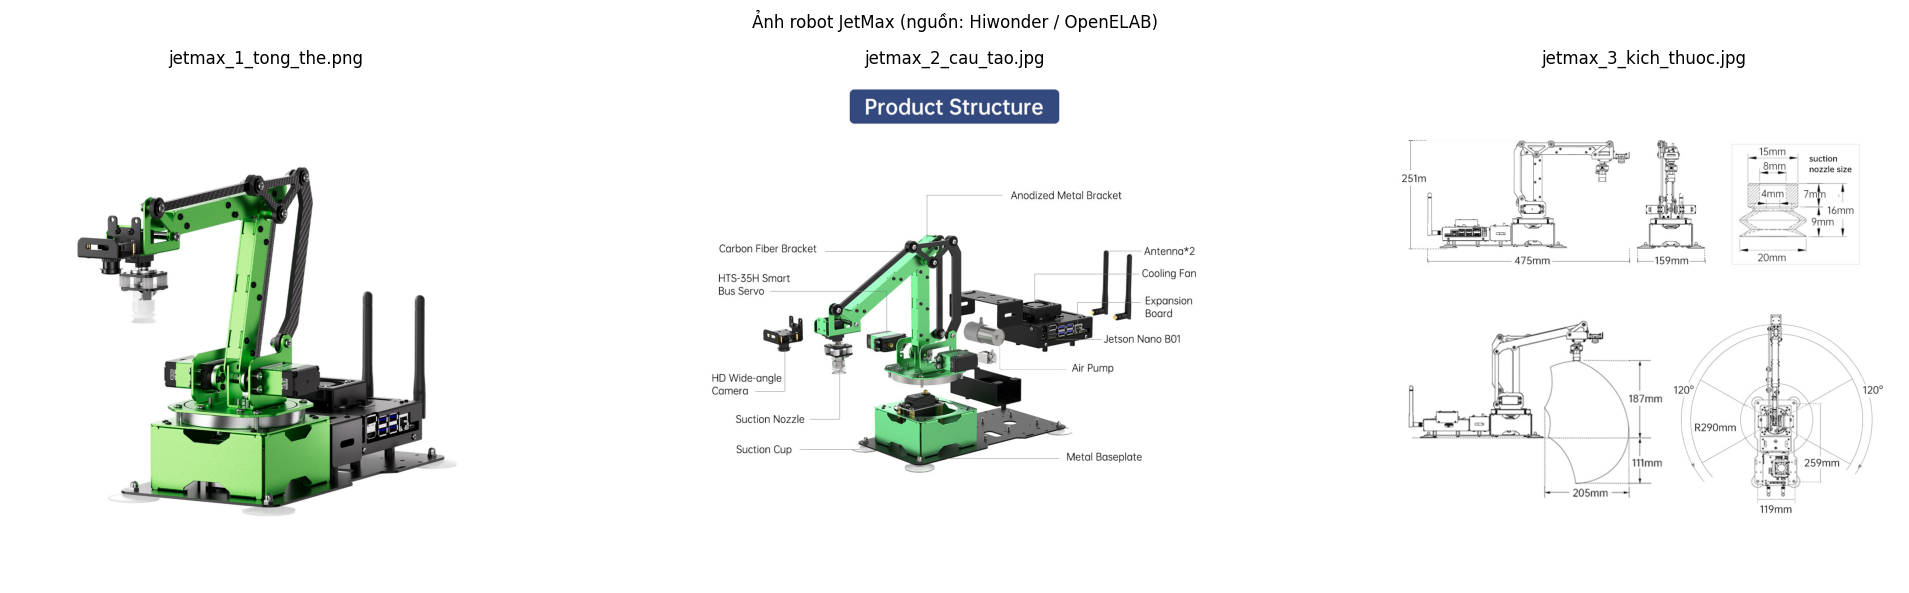

In [23]:
# Tải ảnh JetMax về thư mục images/ (chỉ cần chạy 1 lần, cần Internet) rồi hiển thị.
# Nếu sau này có ảnh tự chụp, chỉ cần đặt vào images/ với tên jetmax_*.jpg là ô này tự hiển thị.
import os, glob, urllib.request
import matplotlib.pyplot as plt
from PIL import Image

IMAGES = {
    'jetmax_1_tong_the.png': 'https://openelab.io/cdn/shop/files/JetMax_c25c4f9f-8f62-4061-872a-20b6e2edcd91.png?v=1783665866&width=1200',
    'jetmax_2_cau_tao.jpg': 'https://openelab.io/cdn/shop/files/6_46904969-a050-4f49-a4f8-0e647cd43a95.jpg?v=1783665866&width=1200',
    'jetmax_3_kich_thuoc.jpg': 'https://openelab.io/cdn/shop/files/11425300d3bcbc36aa2318f39c77fc9b_3149a3f6-4324-4890-9a77-76b9f3051b1c.jpg?v=1783665866&width=1200',
}
os.makedirs('images', exist_ok=True)
for name, url in IMAGES.items():
    path = f'images/{name}'
    if not os.path.exists(path):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=20) as r, open(path, 'wb') as f:
                f.write(r.read())
            print('Đã tải', path)
        except Exception as e:
            print('Không tải được', name, '->', e)

photos = sorted(glob.glob('images/jetmax*.jpg') + glob.glob('images/jetmax*.png'))
if photos:
    fig, axes = plt.subplots(1, len(photos), figsize=(7 * len(photos), 6), squeeze=False)
    for ax, p in zip(axes[0], photos):
        ax.imshow(Image.open(p)); ax.set_title(os.path.basename(p)); ax.axis('off')
    fig.suptitle('Ảnh robot JetMax (nguồn: Hiwonder / OpenELAB)', fontsize=12)
    plt.tight_layout(); plt.show()
else:
    print('Chưa có ảnh trong images/. Mở https://openelab.io/products/hiwonder-jetmax-jetson-nano-robot để lưu thủ công.')

### 1.2 Thông số kỹ thuật cánh tay

| Thông số | Giá trị | Ý nghĩa với đề tài |
|---|---|---|
| Số bậc tự do | **4 + 1** (đế xoay, vai, khuỷu + khớp cổ tay xoay đầu hút) | Đủ để gắp–đặt vật trên mặt phẳng; khớp +1 xoay được quân |
| Tầm với | **104 – 289 mm** tính từ trục đế | ⚠ Giới hạn vùng đặt bàn cờ (xem mục 2) |
| Góc quét của đế | **240°** | Bàn cờ và vùng chứa quân phải nằm trong cung này |
| Độ lặp lại | **±1 mm** | Quân cờ Ø25 mm → sai số rất nhỏ so với kích thước quân |
| Tải trọng | tối đa **450 g** | Quân cờ chỉ vài gram |
| Tốc độ khớp | 0.20 s / 60° | Một lần gắp–đặt mất vài giây |
| Servo | Servo bus thông minh (HTS-35H) + servo chống kẹt (LFD-01M) | Đọc được vị trí từng khớp |
| Cơ cấu chấp hành | Đầu **hút chân không**, kẹp nhỏ, kẹp lớn, bút | Chọn **đầu hút**: mặt quân phẳng, tròn, dày 10 mm |
| Khối lượng / kích thước | ~1.6 kg · ~450 × 160 × 260 mm | |
| Nguồn | 12 V / 5 A | |
| Kết nối | USB, Wi-Fi, Ethernet | Điều khiển từ xa qua Wi-Fi (NoMachine / SSH) |
| Thẻ nhớ | 32 GB microSD | Chứa hệ điều hành + mã nguồn + mô hình |

### 1.3 Bộ điều khiển Jetson Nano và môi trường phần mềm trên robot

| Thành phần | Thông số | Ghi chú |
|---|---|---|
| CPU | 4 nhân ARM Cortex-A57 @ 1.43 GHz | Kiến trúc **ARM (aarch64)**, không phải x86 như laptop |
| GPU | **128 nhân CUDA, kiến trúc Maxwell** (compute capability 5.3) | ~**472 GFLOPS** FP16 — yếu hơn GPU T4 trên Colab hàng chục lần |
| RAM | **4 GB LPDDR4 dùng chung CPU + GPU** | Đo thực tế còn ~3.9 GB khả dụng và **rất ít RAM trống** khi ROS chạy |
| Camera | `/dev/usb_cam0`, **640 × 480**, YUYV | Ảnh đầu vào cho mô hình (đo trên robot) |
| JetPack / L4T | **4.6.1** / R32.6.1 (Ubuntu 18.04) | Bản JetPack cuối cùng hỗ trợ Jetson Nano |
| CUDA | **10.2** | |
| TensorRT | **8.0.1.6** | Quyết định định dạng mô hình (mục 5) |
| Python | **3.6.9** | ⚠ Ultralytics yêu cầu Python ≥ 3.8 → **không cài được trên robot** |
| ROS | ROS 1 Melodic (theo Ubuntu 18.04) | Hệ thống điều khiển của Hiwonder |
| Mạng | **Robot không vào được Internet** | Không `pip install` hay `git clone` trên robot; file được chép từ laptop qua NoMachine |

> Các giá trị JetPack, CUDA, TensorRT, Python, RAM và camera do nhóm **đo trực tiếp trên robot**. Thông số cánh tay lấy từ trang sản phẩm của Hiwonder (xem Tài liệu tham khảo).

### 1.4 Sơ đồ khối hệ thống
Luồng hoạt động của robot: camera → Jetson Nano (nhận diện + tính toán) → bo mở rộng → servo → đầu hút.

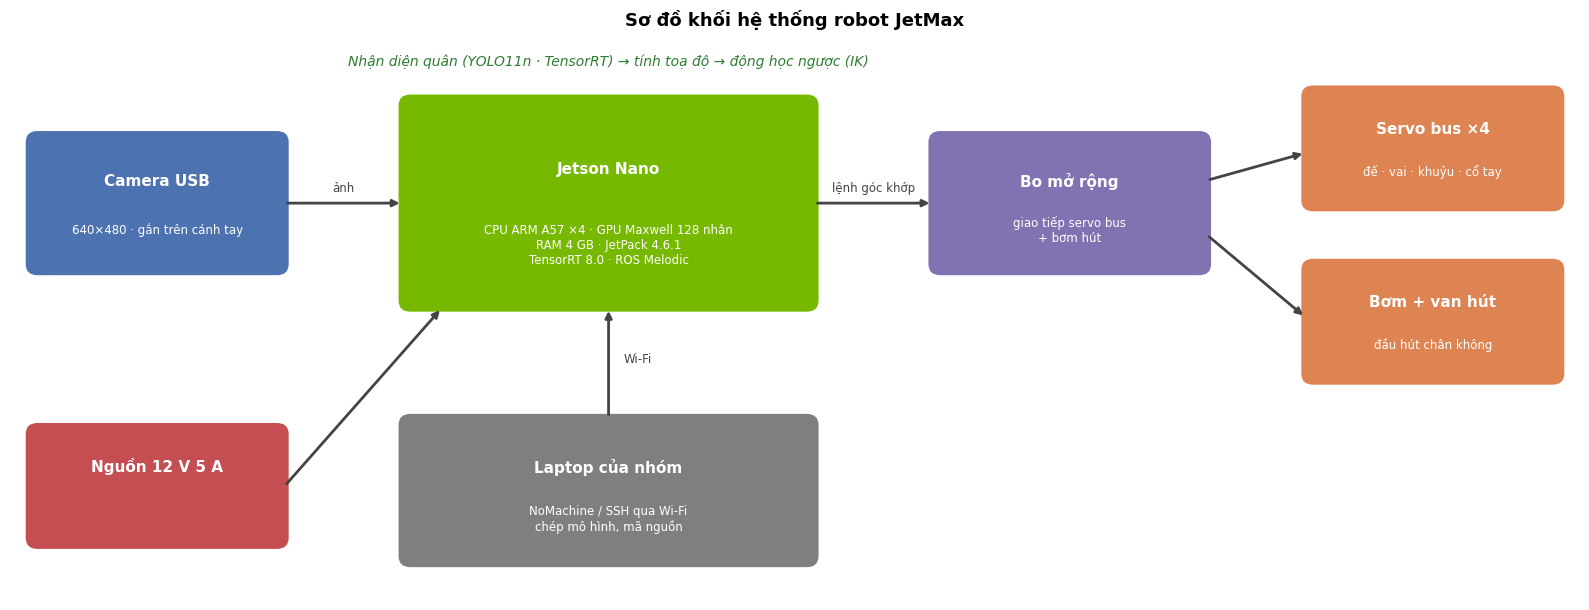

In [24]:
# ── Sơ đồ khối phần cứng JetMax (hình minh hoạ tự vẽ, không phải bản vẽ kỹ thuật của hãng)
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def box(ax, x, y, w, h, title, sub, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.04,rounding_size=0.12', fc=color, ec='none'))
    ax.text(x + w / 2, y + h * 0.66, title, ha='center', va='center', color='white', fontsize=11, fontweight='bold')
    ax.text(x + w / 2, y + h * 0.3, sub, ha='center', va='center', color='white', fontsize=8.5)

def arrow(ax, x0, y0, x1, y1, label=''):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle='-|>', lw=2, color='#444'))
    if label:
        ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.12, label, ha='center', fontsize=8.5, color='#444')

fig, ax = plt.subplots(figsize=(16, 6.2))
ax.set_xlim(0, 16); ax.set_ylim(0, 6.2); ax.axis('off')
box(ax, 0.2, 3.6, 2.6, 1.5, 'Camera USB', '640×480 · gắn trên cánh tay', '#4C72B0')
box(ax, 4.0, 3.2, 4.2, 2.3, 'Jetson Nano', 'CPU ARM A57 ×4 · GPU Maxwell 128 nhân\nRAM 4 GB · JetPack 4.6.1\nTensorRT 8.0 · ROS Melodic', '#76B900')
box(ax, 9.4, 3.6, 2.8, 1.5, 'Bo mở rộng', 'giao tiếp servo bus\n+ bơm hút', '#8172B2')
box(ax, 13.2, 4.3, 2.6, 1.3, 'Servo bus ×4', 'đế · vai · khuỷu · cổ tay', '#DD8452')
box(ax, 13.2, 2.4, 2.6, 1.3, 'Bơm + van hút', 'đầu hút chân không', '#DD8452')
box(ax, 4.0, 0.4, 4.2, 1.6, 'Laptop của nhóm', 'NoMachine / SSH qua Wi-Fi\nchép mô hình, mã nguồn', '#7F7F7F')
box(ax, 0.2, 0.6, 2.6, 1.3, 'Nguồn 12 V 5 A', '', '#C44E52')
arrow(ax, 2.8, 4.35, 4.0, 4.35, 'ảnh')
arrow(ax, 8.2, 4.35, 9.4, 4.35, 'lệnh góc khớp')
arrow(ax, 12.2, 4.6, 13.2, 4.9)
arrow(ax, 12.2, 4.0, 13.2, 3.1)
arrow(ax, 6.1, 2.0, 6.1, 3.2); ax.text(6.25, 2.6, 'Wi-Fi', fontsize=8.5, color='#444')
arrow(ax, 2.8, 1.25, 4.4, 3.2)
ax.text(6.1, 5.85, 'Nhận diện quân (YOLO11n · TensorRT) → tính toạ độ → động học ngược (IK)',
        ha='center', fontsize=10, style='italic', color='#2E7D32')
ax.set_title('Sơ đồ khối hệ thống robot JetMax', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

---
# 2. Không gian làm việc của cánh tay so với bàn cờ

Đây là ràng buộc **quan trọng nhất** khi bố trí hệ thống:
- Tầm với của JetMax: hình vành khăn **104–289 mm** quanh trục đế, trong cung **240°**.
- Bàn cờ nhựa của bộ cờ: **360 × 260 mm**; quân cờ Ø25 mm, dày 10 mm.
- Cạnh dài bàn cờ (360 mm) **lớn hơn bán kính tầm với tối đa** (289 mm) → robot **không thể với tới toàn bộ bàn cờ** khi đặt cố định một chỗ. Điều này khớp với thực tế đã quan sát: robot chỉ gắp được quân từ hàng Xe tới hàng Tốt ở một bên sông.

Ô dưới mô phỏng nhìn từ trên xuống: tô xanh là vùng với tới được, và tính **tỷ lệ diện tích bàn cờ nằm trong tầm với** với hai cách đặt bàn cờ. Có thể chỉnh `NEAR_GAP` (khoảng cách từ trục đế tới mép gần bàn cờ) để thử các cách bố trí khác.

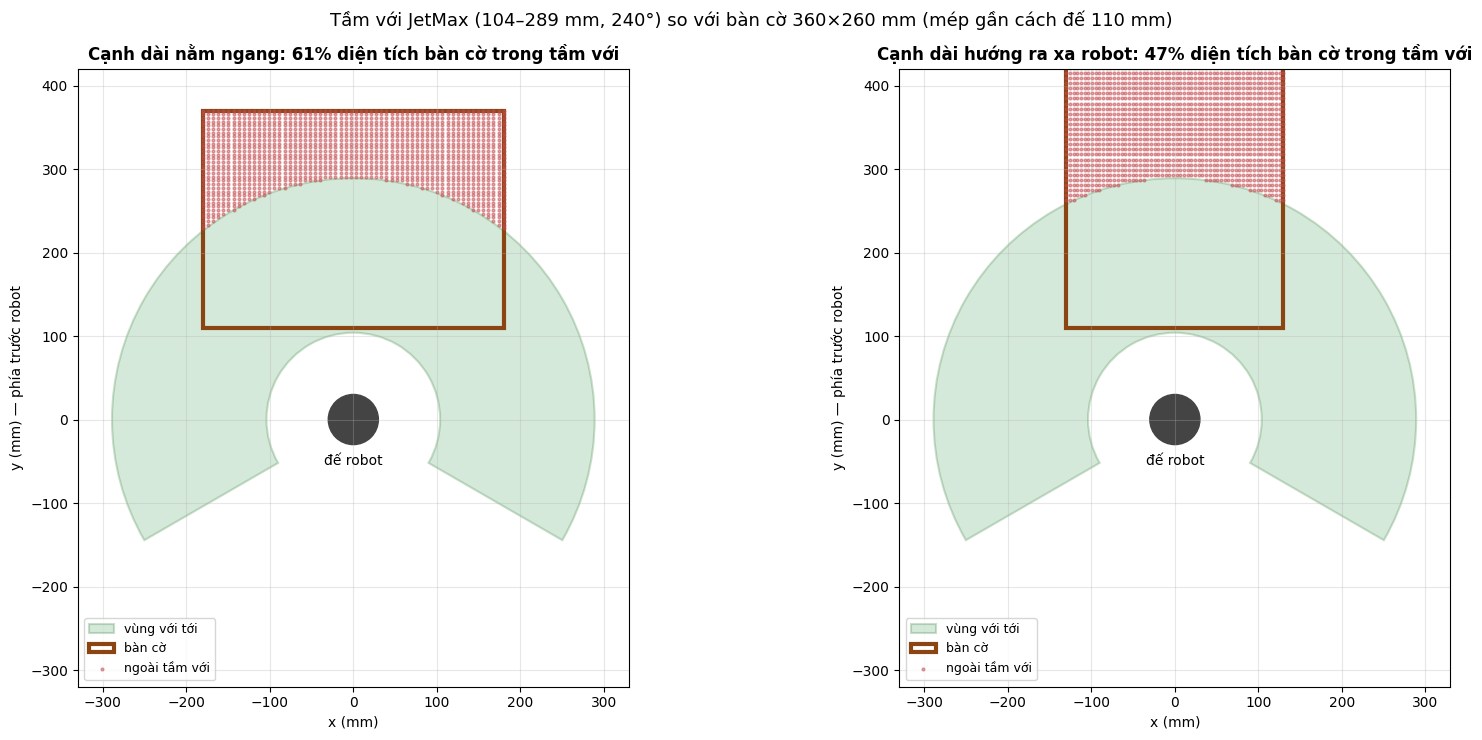

Cạnh dài nằm ngang          : phủ tốt nhất 70% khi mép gần cách đế 80 mm
Cạnh dài hướng ra xa robot  : phủ tốt nhất 53% khi mép gần cách đế 80 mm


In [25]:
# ── Mô phỏng tầm với của JetMax so với bàn cờ (nhìn từ trên xuống, đơn vị mm)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge, Rectangle

R_MIN, R_MAX, SWEEP = 104, 289, 240     # thông số hãng
BOARD_W, BOARD_H = 360, 260             # bàn cờ nhựa của bộ cờ
NEAR_GAP = 110                          # khoảng cách trục đế -> mép gần bàn cờ (thử thay đổi)
MIN_GAP = 80                            # không thể đặt bàn cờ sát hơn (vướng đế robot, giả định)

def reachable(x, y):
    r = np.hypot(x, y)
    ang = np.degrees(np.arctan2(x, y))               # 0° = thẳng phía trước robot
    return (r >= R_MIN) & (r <= R_MAX) & (np.abs(ang) <= SWEEP / 2)

def board_coverage(w, h, gap, n=400):
    xs, ys = np.meshgrid(np.linspace(-w / 2, w / 2, n), np.linspace(gap, gap + h, n))
    return reachable(xs, ys).mean() * 100

layouts = [('Cạnh dài nằm ngang', BOARD_W, BOARD_H), ('Cạnh dài hướng ra xa robot', BOARD_H, BOARD_W)]
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
for ax, (title, w, h) in zip(axes, layouts):
    ax.add_patch(Wedge((0, 0), R_MAX, 90 - SWEEP / 2, 90 + SWEEP / 2, width=R_MAX - R_MIN,
                       fc='#55A868', alpha=0.25, ec='#2E7D32', lw=1.5, label='vùng với tới'))
    ax.add_patch(Rectangle((-w / 2, NEAR_GAP), w, h, fill=False, ec='#8B4513', lw=3, label='bàn cờ'))
    # tô các điểm bàn cờ ngoài tầm với
    xs, ys = np.meshgrid(np.linspace(-w / 2, w / 2, 60), np.linspace(NEAR_GAP, NEAR_GAP + h, 60))
    out = ~reachable(xs, ys)
    ax.scatter(xs[out], ys[out], s=4, color='#C44E52', alpha=0.5, label='ngoài tầm với')
    ax.add_patch(plt.Circle((0, 0), 30, color='#444')); ax.text(0, -55, 'đế robot', ha='center')
    cov = board_coverage(w, h, NEAR_GAP)
    ax.set_title(f'{title}: {cov:.0f}% diện tích bàn cờ trong tầm với', fontsize=12, fontweight='bold')
    ax.set_xlim(-330, 330); ax.set_ylim(-320, 420); ax.set_aspect('equal'); ax.grid(alpha=0.3)
    ax.set_xlabel('x (mm)'); ax.set_ylabel('y (mm) — phía trước robot')
    ax.legend(loc='lower left', fontsize=9)
fig.suptitle(f'Tầm với JetMax ({R_MIN}–{R_MAX} mm, {SWEEP}°) so với bàn cờ {BOARD_W}×{BOARD_H} mm '
             f'(mép gần cách đế {NEAR_GAP} mm)', fontsize=13)
plt.tight_layout(); plt.show()

for title, w, h in layouts:
    # thử các vị trí đặt bàn cờ; không đặt gần hơn MIN_GAP vì vướng thân đế robot (giả định ~80 mm)
    best_gap = max(range(MIN_GAP, 201, 5), key=lambda g: board_coverage(w, h, g, 200))
    print(f'{title:28s}: phủ tốt nhất {board_coverage(w, h, best_gap):.0f}% khi mép gần cách đế {best_gap} mm')

> **Hệ quả cho thiết kế:** không có cách đặt bàn cờ cố định nào để robot với tới **mọi** giao điểm. Các hướng giải quyết cần cân nhắc:
> 1. **Thu hẹp phạm vi:** chỉ xếp quân vào phần bàn cờ nằm trong tầm với (vd. nửa bàn cờ của một bên).
> 2. **Dùng bàn cờ nhỏ hơn** (vd. in khổ A4, 297 × 210 mm) để toàn bộ nằm trong vùng xanh — đánh đổi: ô nhỏ hơn, quân Ø25 mm có thể sát nhau.
> 3. **Mở rộng phần cứng:** Hiwonder có phụ kiện **ray trượt** (sliding rail) cho JetMax, giúp robot di chuyển dọc bàn cờ.
> 4. Camera gắn trên tay nên ở mỗi vị trí chỉ thấy một phần bàn cờ → robot cần **di chuyển để quan sát** (chụp nhiều góc) rồi ghép kết quả.

---
# 3. Cần chuẩn bị gì để làm việc với JetMax?

### 3.1 Phần cứng

| Hạng mục | Chi tiết | Ghi chú |
|---|---|---|
| Robot JetMax | Cánh tay + Jetson Nano + camera + **đầu hút** | Kiểm tra bơm hút và ống dẫn khí trước mỗi buổi |
| Nguồn | Adapter 12 V 5 A | Nguồn yếu làm servo giật, Jetson tự khởi động lại |
| Bàn cờ + bộ quân | Bàn cờ 360 × 260 mm, quân Ø25 mm × 10 mm | Mặt quân phẳng → đầu hút giữ chắc |
| Mặt bàn + ánh sáng | Mặt phẳng, màu đơn sắc, ánh sáng đều | Tránh bóng đổ và phản chiếu lên mặt quân |
| Laptop | Cùng mạng Wi-Fi với robot | Dùng để lập trình, train, chép file |
| Thẻ nhớ dự phòng | Sao lưu image hệ điều hành của robot | Phòng khi hỏng hệ thống |

### 3.2 Phần mềm và thư viện — chia theo **nơi chạy**

| Nơi chạy | Thành phần | Dùng để làm gì |
|---|---|---|
| **Google Colab** (GPU T4) | Python 3.10+, **PyTorch**, **Ultralytics** (YOLO11) | Xây dựng dataset, huấn luyện, đánh giá mô hình |
| | `onnx`, `onnxslim`, `onnxruntime` | Xuất và kiểm tra file ONNX |
| | `roboflow`, `imagehash`, `scikit-learn`, `pandas`, `matplotlib` | Tải và xử lý dữ liệu, vẽ biểu đồ |
| | Mã nguồn **Pikafish** + `g++-aarch64-linux-gnu` | Build sẵn engine cờ tướng cho CPU ARM của robot (Bước 5) |
| **Laptop** | **NoMachine** (client) | Màn hình từ xa + **chép file** sang robot (robot không có Internet) |
| | Git + GitHub | Quản lý mã nguồn (`xiangqi-sorting-jetmax`) |
| | VS Code, Python | Viết mã cho robot |
| **Robot JetMax** | **JetPack 4.6.1**: Ubuntu 18.04, CUDA 10.2, cuDNN, **TensorRT 8.0.1.6** | Chạy mô hình bằng GPU |
| | `trtexec` (đi kèm TensorRT) | Build `best.engine` từ `best.onnx` |
| | Python 3.6.9 + `tensorrt` + `pycuda` + `numpy` | Gọi engine từ Python |
| | **OpenCV** | Đọc camera, xử lý ảnh, tìm bàn cờ, tính toạ độ |
| | **ROS Melodic** + gói điều khiển của Hiwonder | Điều khiển servo, đầu hút, động học ngược (IK) |
| | **Pikafish** (file chạy aarch64 link tĩnh) + mạng `pikafish.nnue` | Engine cờ tướng: tìm nước đi tiếp theo, chạy trên **CPU** |
| | NoMachine (server) | Nhận kết nối từ laptop |

> ⚠ **Hai thư viện quan trọng nhất không chạy được trên robot:** PyTorch và Ultralytics (Python 3.6 quá cũ, robot không có Internet để cài). Vì vậy phía robot chỉ dùng **TensorRT + OpenCV + NumPy**. Đây chính là lý do phải chuyển đổi mô hình (mục 5).

### 3.3 Quy trình làm việc hằng ngày với robot
1. Bật nguồn robot, chờ Jetson khởi động, robot về tư thế ban đầu.
2. Laptop kết nối robot qua **NoMachine** (cùng mạng Wi-Fi).
3. Chép mã nguồn / mô hình mới từ laptop sang robot qua NoMachine.
4. Chạy chương trình trên robot (terminal trong NoMachine), quan sát bằng cửa sổ camera.
5. Sao lưu kết quả (ảnh, log) ngược về laptop rồi commit lên GitHub.

---
# 4. Kế hoạch xây dựng robot đánh cờ tướng

Một robot "đánh cờ" phải trả lời được 4 câu hỏi theo vòng lặp **Nhìn → Hiểu → Quyết định → Hành động**:

| Vòng lặp | Câu hỏi | Thành phần | Công nghệ |
|---|---|---|---|
| **Nhìn** | Quân nào, nằm ở đâu trong ảnh? | Nhận diện quân cờ | YOLO11n → TensorRT |
| **Hiểu** | Quân đó đứng ở giao điểm nào trên bàn? | Nhận diện bàn cờ + ánh xạ pixel → ô cờ → mm | OpenCV (tìm bàn cờ, homography), hiệu chuẩn camera |
| **Quyết định** | Người vừa đi nước nào? Robot đi nước nào? | Luật cờ: kiểm tra thế cờ, suy ra nước vừa đi, sửa lỗi nhận diện; engine chọn nước đi | `board/rules.py`; **Pikafish** qua giao thức UCI |
| **Hành động** | Di chuyển cánh tay thế nào? | Gắp–đặt bằng đầu hút | Động học ngược (IK) của Hiwonder, ROS |

### Các giai đoạn thực hiện

Mục tiêu của đề tài: một **thư viện** nhận **ảnh bàn cờ + thế cờ ở lượt trước** và trả về **nước đi tiếp theo**; chương trình trên robot gọi thư viện này rồi điều khiển tay máy đi quân. Mỗi giai đoạn tương ứng một notebook (một mục trong báo cáo):

| # | Giai đoạn | Notebook / mã nguồn | Đầu ra | Trạng thái |
|---|---|---|---|---|
| 1 | Xây dựng dataset 14 lớp quân cờ | `build_dataset.ipynb` | `merged_v1` (6 808 ảnh) | ✅ Xong |
| 2 | Huấn luyện YOLO11n, xoay mọi hướng | `train_yolo11.ipynb` | `best.pt`, mAP@0.5 test = 0.968 | ✅ Xong |
| 3 | Giới thiệu robot; đưa mô hình và engine lên robot | **notebook này** | `best.engine` (GPU), Pikafish (CPU) chạy trên Jetson | ✅ Mô hình · 🔄 Engine (mục 6, Bước 4) |
| 4 | **Ảnh → thế cờ (FEN):** định vị bàn cờ, lưới 9 × 10, gán quân vào giao điểm | `board_to_fen.ipynb`; `vision/` | FEN + độ chính xác trên ảnh thật | 🔄 Đang làm (cần bộ ảnh thật từ camera robot) |
| 5 | **Luật cờ + engine:** kiểm tra thế cờ, suy ra nước người vừa đi, sửa lỗi nhận diện, Pikafish | `rules_engine.ipynb`; `board/rules.py`, `brain/` | Nước đi tiếp theo; `pikafish_jetson.tar.gz` | ✅ Xong |
| 6 | **Đóng gói thư viện:** ảnh + thế trước → nước tiếp theo | gói mã nguồn + `demo.ipynb` | API cho chương trình robot | ⏳ Tiếp theo |
| 7 | **Tích hợp tay máy và đánh giá:** hiệu chuẩn camera–robot, gắp–đặt, đi quân, đo trên robot | `eval_robot.ipynb`; `robot/`, `tools/calibrate.py` | Số liệu end-to-end cho báo cáo | 🔄 Đang làm (hiệu chuẩn, gắp–đặt A → B) |

### Biểu diễn trạng thái bàn cờ
Sau bước "Hiểu", bàn cờ được biểu diễn thành **ma trận 10 hàng × 9 cột**, rồi chuyển sang chuỗi **FEN**, định dạng chuẩn mà engine cờ tướng đọc được. Ký hiệu FEN của 14 lớp đã được định nghĩa từ lúc xây dựng dataset (`a b c k n p r` cho quân đen, chữ hoa cho quân đỏ). Ví dụ thế cờ ban đầu:
```
rnbakabnr/9/1c5c1/p1p1p1p1p/9/9/P1P1P1P1P/1C5C1/9/RNBAKABNR w
```

In [ ]:
# ── Sơ đồ vòng lặp và tiến độ các giai đoạn (minh hoạ)
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

stages = [
    ('1. Dataset', 'done'), ('2. Train\nYOLO11n', 'done'), ('3. Robot +\ntriển khai', 'done'),
    ('4. Ảnh → FEN', 'doing'), ('5. Luật cờ +\nPikafish', 'done'), ('6. Đóng gói\nthư viện', 'next'),
    ('7. Tích hợp tay\nmáy + đánh giá', 'doing'),
]
COL = {'done': '#55A868', 'doing': '#DD8452', 'next': '#4C72B0', 'idea': '#9E9E9E'}
LBL = {'done': 'Đã xong', 'doing': 'Đang làm', 'next': 'Tiếp theo'}
COL.pop('idea')

fig, axes = plt.subplots(2, 1, figsize=(17, 8), gridspec_kw={'height_ratios': [1, 1.1]})
ax = axes[0]; ax.set_xlim(0, 16); ax.set_ylim(-0.7, 2.4); ax.axis('off')
loop = [('NHÌN', 'YOLO11n · TensorRT', '#4C72B0'), ('HIỂU', 'bàn cờ · homography · FEN', '#8172B2'),
        ('QUYẾT ĐỊNH', 'luật cờ · Pikafish', '#C44E52'), ('HÀNH ĐỘNG', 'IK · đầu hút', '#DD8452')]
for i, (t, s, c) in enumerate(loop):
    x = 0.4 + i * 4
    ax.add_patch(FancyBboxPatch((x, 0.5), 3.0, 1.4, boxstyle='round,pad=0.05,rounding_size=0.2', fc=c, ec='none'))
    ax.text(x + 1.5, 1.4, t, ha='center', color='white', fontsize=13, fontweight='bold')
    ax.text(x + 1.5, 0.85, s, ha='center', color='white', fontsize=9.5)
    if i < 3:
        ax.annotate('', xy=(x + 3.9, 1.2), xytext=(x + 3.1, 1.2), arrowprops=dict(arrowstyle='-|>', lw=2.5, color='#444'))
ax.annotate('', xy=(1.9, 0.4), xytext=(13.9, 0.4),
            arrowprops=dict(arrowstyle='-|>', lw=1.5, color='#888', connectionstyle='arc3,rad=-0.08'))
ax.text(8, -0.55, 'lặp lại sau mỗi nước đi', ha='center', color='#888', fontsize=9)
ax.set_title('Vòng lặp hoạt động của robot đánh cờ', fontsize=13, fontweight='bold')

ax = axes[1]; ax.set_xlim(0, 16.4); ax.set_ylim(0, 2.6); ax.axis('off')
for i, (t, st) in enumerate(stages):
    x = 0.2 + i * 2.33
    ax.add_patch(FancyBboxPatch((x, 0.8), 2.05, 1.3, boxstyle='round,pad=0.04,rounding_size=0.15', fc=COL[st], ec='none'))
    ax.text(x + 1.02, 1.45, t, ha='center', va='center', color='white', fontsize=9.5, fontweight='bold')
    if i < len(stages) - 1:
        ax.annotate('', xy=(x + 2.32, 1.45), xytext=(x + 2.08, 1.45), arrowprops=dict(arrowstyle='-|>', color='#444'))
for k, (st, c) in enumerate(COL.items()):
    ax.add_patch(plt.Rectangle((4 + k * 2.4, 0.2), 0.3, 0.3, color=c)); ax.text(4.4 + k * 2.4, 0.35, LBL[st], va='center')
ax.set_title('Tiến độ các giai đoạn', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

---
# 5. Vì sao mô hình phải qua 3 dạng: `best.pt` → `best.onnx` → `best.engine`?

> **Lưu ý thuật ngữ:** tạo `best.engine` trên robot là **build (biên dịch / tối ưu hoá)**, **không phải train**. Trọng số đã học xong trên Colab, giữ nguyên. TensorRT chỉ sắp xếp lại cách tính toán sao cho nhanh nhất trên GPU của Jetson Nano.

| | `best.pt` | `best.onnx` | `best.engine` |
|---|---|---|---|
| **Là gì** | Checkpoint PyTorch: trọng số + kiến trúc + thông tin train | Đồ thị tính toán ở **định dạng mở, trung lập** | Mô hình đã được TensorRT **biên dịch** cho đúng một GPU |
| **Tạo ở đâu** | Colab (sau khi train) | Colab (`model.export(format='onnx', opset=12)`) | **Trên chính Jetson Nano** (`trtexec`) |
| **Cần gì để chạy** | Python ≥ 3.8 + PyTorch + Ultralytics | onnxruntime / OpenCV DNN / TensorRT | TensorRT **đúng phiên bản** (8.0.1.6) + **đúng GPU** (Maxwell sm_53) |
| **Chạy được trên robot?** | ❌ Python 3.6, không có Ultralytics | ⚠ Được, nhưng chậm (chạy CPU hoặc chưa tối ưu) | ✅ **Nhanh nhất**, dùng GPU + FP16 |
| **Mang sang máy khác?** | ✅ Máy nào có PyTorch | ✅ **Mọi nền tảng** | ❌ **Không** — chỉ chạy trên máy đã build |
| **Dùng để** | Train tiếp, đánh giá, export | **Cầu nối** giữa PyTorch và TensorRT | **Chạy thật trên robot** |

### 5.1 Vì sao không chạy thẳng `best.pt` trên robot?
1. **Phần mềm:** `.pt` cần PyTorch + Ultralytics. Ultralytics yêu cầu **Python ≥ 3.8**, robot chỉ có **Python 3.6.9** (JetPack 4.x); robot cũng **không có Internet** để cài thêm.
2. **Hiệu năng:** PyTorch chạy mô hình theo từng lớp, chưa được tối ưu cho GPU Maxwell nhỏ và RAM 4 GB dùng chung.

### 5.2 Vì sao cần bước trung gian `best.onnx`?
- TensorRT **không đọc được** file `.pt`. Nó nhận mô hình qua **ONNX**, định dạng chuẩn mở để trao đổi mô hình giữa các framework.
- File ONNX độc lập nền tảng, nên tạo được trên Colab (x86 + GPU T4) rồi chép sang robot (ARM + Jetson).
- Xuất với **`opset=12`**: TensorRT 8.0 trên JetPack 4.6 chỉ hỗ trợ tới một mức opset nhất định; opset 12 là mức an toàn.
- `simplify=True` gộp/bỏ các node thừa, giúp TensorRT build dễ hơn.

### 5.3 Vì sao phải build `best.engine` **trên robot**, không build sẵn trên Colab?
Khi build, TensorRT thực hiện các tối ưu **gắn chặt với phần cứng và phiên bản**:
- **Gộp lớp** (layer fusion): ví dụ Conv + BatchNorm + SiLU thành một kernel, giảm số lần đọc/ghi bộ nhớ.
- **Chọn kernel nhanh nhất** (auto-tuning): đo thử nhiều cách cài đặt mỗi phép tính **trên chính GPU đó** rồi chọn cách nhanh nhất.
- **Hạ độ chính xác FP32 → FP16** (`--fp16`): giảm một nửa bộ nhớ, tăng tốc trên GPU hỗ trợ FP16, độ chính xác gần như không đổi.
- **Cấp phát bộ nhớ cố định** cho kích thước đầu vào 1 × 3 × 640 × 640.

Kết quả là file engine chỉ đúng với **GPU đã build** và **phiên bản TensorRT đã build**:

| | Colab | Robot JetMax |
|---|---|---|
| GPU | Tesla T4 (Turing, sm_75) | Jetson Nano (Maxwell, sm_53) |
| CPU | x86-64 | ARM aarch64 |
| TensorRT | 10.x | 8.0.1.6 |

Engine build trên Colab sẽ **không nạp được** trên robot (khác GPU, khác CPU, khác phiên bản TensorRT). Vì vậy quy trình bắt buộc là: **chép `best.onnx` sang robot → build `best.engine` ngay trên robot.**

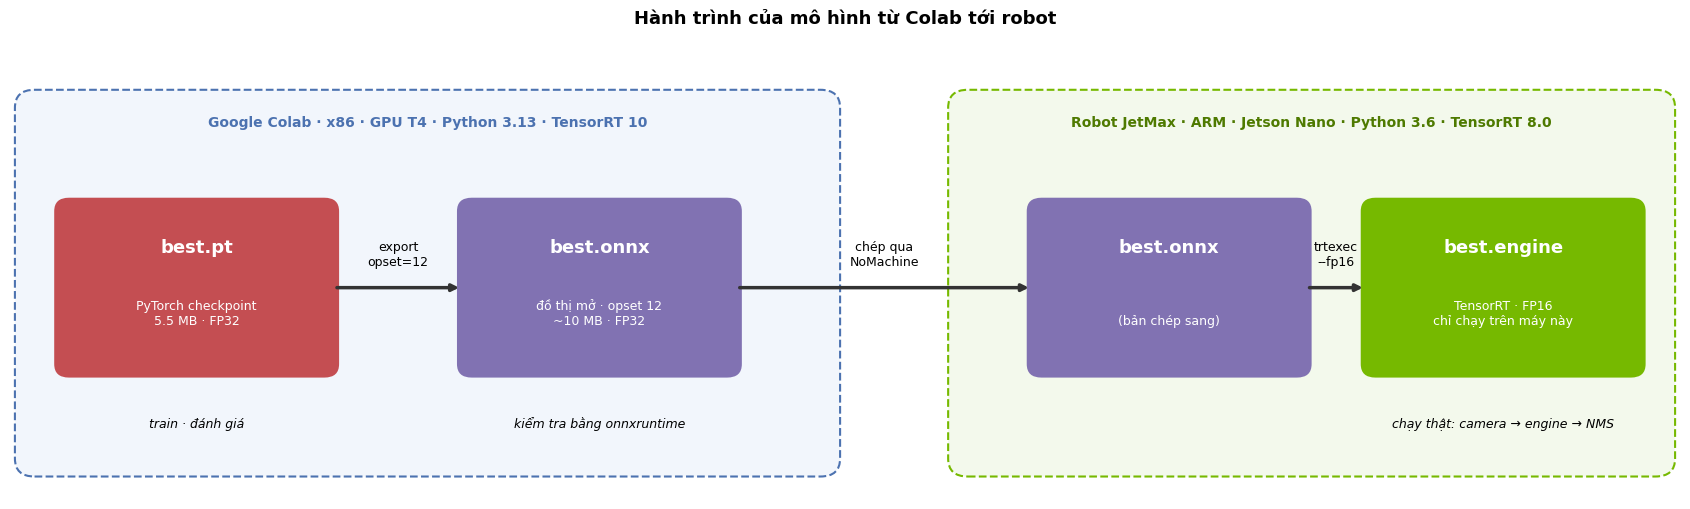

In [27]:
# ── Sơ đồ chuyển đổi mô hình (minh hoạ)
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(17, 5.2))
ax.set_xlim(0, 17); ax.set_ylim(0, 5.2); ax.axis('off')
ax.add_patch(FancyBboxPatch((0.1, 0.3), 8.3, 4.2, boxstyle='round,pad=0.05,rounding_size=0.2', fc='#F2F6FC', ec='#4C72B0', lw=1.5, ls='--'))
ax.text(4.25, 4.15, 'Google Colab · x86 · GPU T4 · Python 3.13 · TensorRT 10', ha='center', color='#4C72B0', fontweight='bold')
ax.add_patch(FancyBboxPatch((9.6, 0.3), 7.3, 4.2, boxstyle='round,pad=0.05,rounding_size=0.2', fc='#F3F9EC', ec='#76B900', lw=1.5, ls='--'))
ax.text(13.25, 4.15, 'Robot JetMax · ARM · Jetson Nano · Python 3.6 · TensorRT 8.0', ha='center', color='#4E7A00', fontweight='bold')

items = [
    (0.5, 'best.pt', 'PyTorch checkpoint\n5.5 MB · FP32', '#C44E52'),
    (4.6, 'best.onnx', 'đồ thị mở · opset 12\n~10 MB · FP32', '#8172B2'),
    (10.4, 'best.onnx', '(bản chép sang)', '#8172B2'),
    (13.8, 'best.engine', 'TensorRT · FP16\nchỉ chạy trên máy này', '#76B900'),
]
for x, t, s, c in items:
    ax.add_patch(FancyBboxPatch((x, 1.4), 2.8, 1.9, boxstyle='round,pad=0.05,rounding_size=0.15', fc=c, ec='none'))
    ax.text(x + 1.4, 2.75, t, ha='center', color='white', fontsize=13, fontweight='bold')
    ax.text(x + 1.4, 1.95, s, ha='center', color='white', fontsize=9)
for (x0, x1, lab) in [(3.3, 4.6, 'export\nopset=12'), (7.4, 10.4, 'chép qua\nNoMachine'), (13.2, 13.8, 'trtexec\n--fp16')]:
    ax.annotate('', xy=(x1, 2.35), xytext=(x0, 2.35), arrowprops=dict(arrowstyle='-|>', lw=2.5, color='#333'))
    ax.text((x0 + x1) / 2, 2.6, lab, ha='center', fontsize=9)
ax.text(1.9, 0.8, 'train · đánh giá', ha='center', fontsize=9, style='italic')
ax.text(6.0, 0.8, 'kiểm tra bằng onnxruntime', ha='center', fontsize=9, style='italic')
ax.text(15.2, 0.8, 'chạy thật: camera → engine → NMS', ha='center', fontsize=9, style='italic')
ax.set_title('Hành trình của mô hình từ Colab tới robot', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

### 5.4 Thực nghiệm: so sánh `best.pt` và `best.onnx`
Chạy hai ô dưới trên **Colab** (cùng tài khoản Drive với notebook train) để chứng minh hai điều:
1. **ONNX tính ra cùng kết quả với PyTorch:** so sánh trực tiếp tensor đầu ra `(1, 18, 8400)` trên cùng một ảnh test, sai lệch phải gần 0.
2. **Bên trong file ONNX là gì:** opset, kích thước đầu vào/đầu ra, các loại phép tính (node). TensorRT 8.0 phải hỗ trợ được tất cả các phép này.

**Ô chuẩn bị:** kết nối Google Drive, tìm `best.pt` / `best.onnx` và ảnh test. Nếu có `best.pt` mà chưa có `best.onnx`, ô sẽ tự xuất ONNX (opset 12) giống notebook train. Các vị trí được tìm lần lượt:
1. Drive: `MyDrive/datn/runs/yolo11n_640_rot/weights/` (nơi notebook train lưu)
2. Thư mục repo: `runs/yolo11n_640_rot/weights/`, `robot/models/`, `weights/`
3. Mọi file `best.pt` trong `MyDrive/datn/` (nếu đổi tên thư mục run)

In [28]:
import os, sys, glob, shutil

# ── 1) Kết nối Google Drive (chỉ khi chạy trên Colab)
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB and not os.path.isdir('/content/drive/MyDrive'):
    from google.colab import drive
    drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/datn'
RUN_NAME = 'yolo11n_640_rot'                  # đổi nếu run của bạn có tên khác

# ── 2) Tìm thư mục chứa best.pt
candidates = [f'{BASE}/runs/{RUN_NAME}/weights', f'runs/{RUN_NAME}/weights', f'../runs/{RUN_NAME}/weights',
              'robot/models', '../robot/models', 'weights', '.']
RUN = next((d for d in candidates if os.path.exists(f'{d}/best.pt')), None)
if RUN is None:
    found = sorted(glob.glob(f'{BASE}/**/best.pt', recursive=True)) if os.path.isdir(BASE) else []
    print('Không thấy best.pt ở các vị trí mặc định.')
    print('Các file best.pt tìm thấy trên Drive:', *found, sep='\n  ') if found else print('Drive không có best.pt nào.')
    raise FileNotFoundError('Sửa RUN_NAME cho đúng, hoặc tải best.pt lên Colab (biểu tượng thư mục bên trái) '
                            'vào thư mục weights/ rồi chạy lại ô này.')
PT, ONNX = f'{RUN}/best.pt', f'{RUN}/best.onnx'
print('best.pt   :', PT)

# ── 3) Cài thư viện nếu thiếu
try:
    import onnx, onnxruntime, ultralytics  # noqa: F401
except ImportError:
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics', 'onnx', 'onnxruntime', 'onnxslim'],
                   check=True)

# ── 4) Có best.pt mà chưa có best.onnx -> tự xuất (giống notebook train)
if not os.path.exists(ONNX):
    from ultralytics import YOLO
    print('Chưa có best.onnx -> xuất từ best.pt (opset 12)...')
    ONNX = str(YOLO(PT).export(format='onnx', imgsz=640, opset=12, simplify=True))
print('best.onnx :', ONNX)

# ── 5) Ảnh test: giải nén merged_v1.zip nếu chưa có
MERGED = '/content/merged'
TEST_DIR = f'{MERGED}/test/images'
if not glob.glob(f'{TEST_DIR}/*') and os.path.exists(f'{BASE}/merged/merged_v1.zip'):
    print('Giải nén merged_v1.zip ...')
    shutil.unpack_archive(f'{BASE}/merged/merged_v1.zip', MERGED)
if not glob.glob(f'{TEST_DIR}/*'):
    for alt in ['images', 'test_images', '../images']:       # dự phòng: ảnh bất kỳ trong repo
        if glob.glob(f'{alt}/*.jpg') + glob.glob(f'{alt}/*.png'):
            TEST_DIR = alt; break
print('Ảnh test  :', TEST_DIR, f'({len(glob.glob(TEST_DIR + "/*"))} ảnh)')

best.pt   : /content/drive/MyDrive/datn/runs/yolo11n_640_rot/weights/best.pt
best.onnx : /content/drive/MyDrive/datn/runs/yolo11n_640_rot/weights/best.onnx
Ảnh test  : /content/merged/test/images (713 ảnh)


,best.pt,best.onnx
Kích thước file,5.5 MB,10.7 MB
Định dạng,PyTorch + Ultralytics,ONNX (mở)
Số tham số,2.61 M,2.61 M
Opset,—,12
Đầu vào,—,"[1, 3, 640, 640]"
Đầu ra,—,"[1, 18, 8400]"


Đầu ra PyTorch (1, 18, 8400) | ONNX (1, 18, 8400)
Sai lệch tuyệt đối: lớn nhất 1.07e-03 · trung bình 5.63e-06
Lớp dự đoán trùng nhau (ô có điểm > 0.5): 100.0%


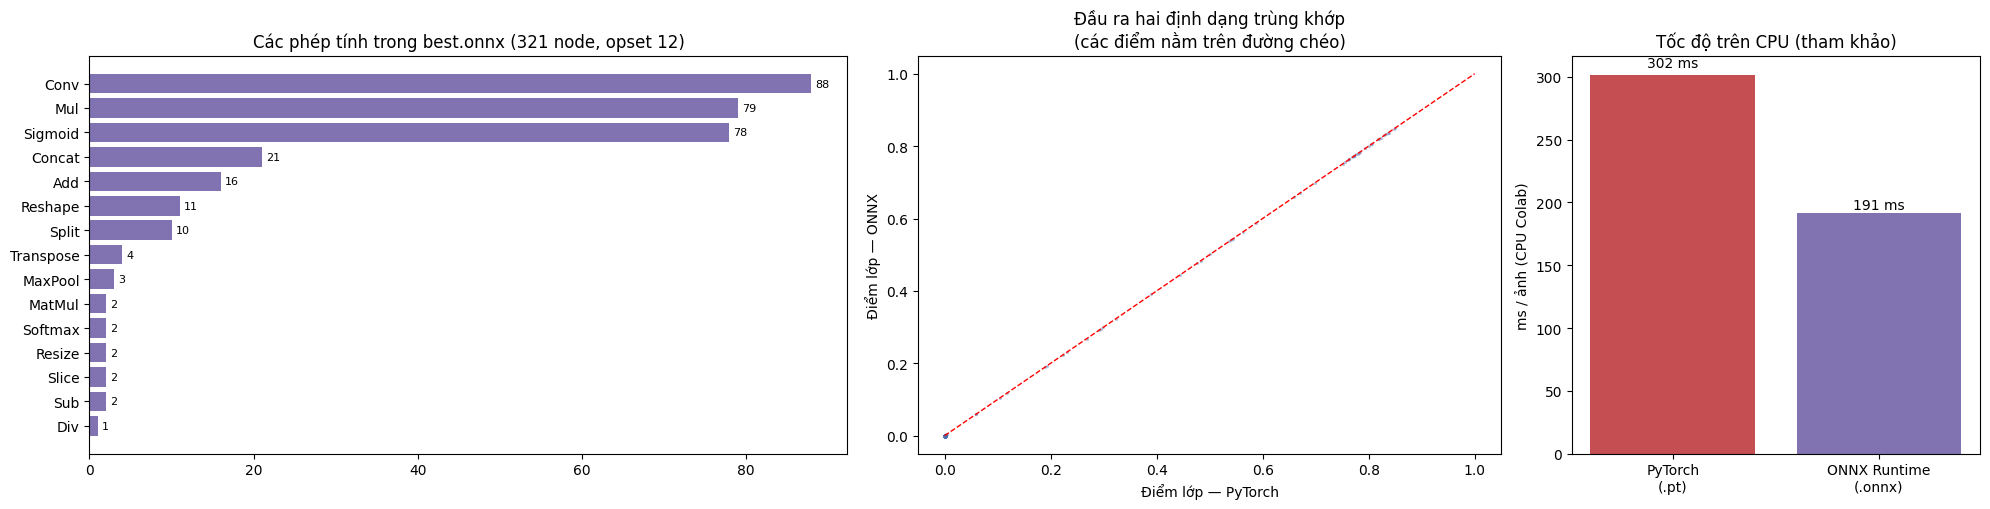

In [29]:
import os, glob, time, random
from collections import Counter
import numpy as np, cv2, pandas as pd
import matplotlib.pyplot as plt

# PT, ONNX, TEST_DIR lấy từ ô chuẩn bị phía trên
try:
    import onnx, onnxruntime as ort, torch
    from ultralytics import YOLO
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics', 'onnx', 'onnxruntime'], check=True)
    import onnx, onnxruntime as ort, torch
    from ultralytics import YOLO

# ── 1) Thông tin hai file
yolo = YOLO(PT)
n_params = sum(p.numel() for p in yolo.model.parameters())
om = onnx.load(ONNX)
shape = lambda v: [d.dim_value for d in v.type.tensor_type.shape.dim]
info = pd.DataFrame({
    'best.pt': [f'{os.path.getsize(PT) / 1e6:.1f} MB', 'PyTorch + Ultralytics', f'{n_params / 1e6:.2f} M', '—', '—', '—'],
    'best.onnx': [f'{os.path.getsize(ONNX) / 1e6:.1f} MB', 'ONNX (mở)', f'{n_params / 1e6:.2f} M',
                  om.opset_import[0].version, str(shape(om.graph.input[0])), str(shape(om.graph.output[0]))],
}, index=['Kích thước file', 'Định dạng', 'Số tham số', 'Opset', 'Đầu vào', 'Đầu ra'])
display(info)

# ── 2) So sánh đầu ra thô trên cùng một ảnh test (đã letterbox về 640×640)
def letterbox(img, size=640):
    h, w = img.shape[:2]; s = min(size / h, size / w)
    nh, nw = round(h * s), round(w * s); top, left = (size - nh) // 2, (size - nw) // 2
    canvas = np.full((size, size, 3), 114, np.uint8)
    canvas[top:top + nh, left:left + nw] = cv2.resize(img, (nw, nh))
    return canvas

img_path = random.Random(0).choice(sorted(glob.glob(f'{TEST_DIR}/*')))
blob = letterbox(cv2.imread(img_path))[:, :, ::-1].transpose(2, 0, 1)[None].astype(np.float32) / 255.0

net = yolo.model.float().eval()
with torch.no_grad():
    out_pt = net(torch.from_numpy(blob.copy()))
    out_pt = (out_pt[0] if isinstance(out_pt, (list, tuple)) else out_pt).numpy()
sess = ort.InferenceSession(ONNX, providers=['CPUExecutionProvider'])
out_onnx = sess.run(None, {sess.get_inputs()[0].name: blob})[0]

diff = np.abs(out_pt - out_onnx)
print(f'Đầu ra PyTorch {out_pt.shape} | ONNX {out_onnx.shape}')
print(f'Sai lệch tuyệt đối: lớn nhất {diff.max():.2e} · trung bình {diff.mean():.2e}')
print(f'Lớp dự đoán trùng nhau (ô có điểm > 0.5): '
      f'{(out_pt[0, 4:].argmax(0) == out_onnx[0, 4:].argmax(0))[out_pt[0, 4:].max(0) > 0.5].mean() * 100:.1f}%'
      if (out_pt[0, 4:].max(0) > 0.5).any() else 'Không có ô nào điểm > 0.5')

# ── 3) Tốc độ trên CPU (tham khảo, chỉ để so sánh tương đối)
def bench(fn, n=20):
    fn(); t = time.perf_counter()
    for _ in range(n): fn()
    return (time.perf_counter() - t) / n * 1000
t_pt = bench(lambda: net(torch.from_numpy(blob.copy())))
t_onnx = bench(lambda: sess.run(None, {sess.get_inputs()[0].name: blob}))

# ── 4) Biểu đồ: các loại phép tính trong ONNX + so sánh đầu ra + tốc độ CPU
ops = Counter(n.op_type for n in om.graph.node)
fig, axes = plt.subplots(1, 3, figsize=(20, 5.2), gridspec_kw={'width_ratios': [1.3, 1, 0.7]})
names_, counts_ = zip(*ops.most_common())
axes[0].barh(names_, counts_, color='#8172B2'); axes[0].invert_yaxis()
axes[0].set_title(f'Các phép tính trong best.onnx ({len(om.graph.node)} node, opset {om.opset_import[0].version})')
for i, v in enumerate(counts_):
    axes[0].text(v + 0.5, i, str(v), va='center', fontsize=8)
axes[1].scatter(out_pt[0, 4:].ravel(), out_onnx[0, 4:].ravel(), s=2, alpha=0.3, color='#4C72B0')
axes[1].plot([0, 1], [0, 1], 'r--', lw=1)
axes[1].set_xlabel('Điểm lớp — PyTorch'); axes[1].set_ylabel('Điểm lớp — ONNX')
axes[1].set_title('Đầu ra hai định dạng trùng khớp\n(các điểm nằm trên đường chéo)')
axes[2].bar(['PyTorch\n(.pt)', 'ONNX Runtime\n(.onnx)'], [t_pt, t_onnx], color=['#C44E52', '#8172B2'])
for i, v in enumerate([t_pt, t_onnx]):
    axes[2].text(i, v * 1.02, f'{v:.0f} ms', ha='center')
axes[2].set_ylabel('ms / ảnh (CPU Colab)'); axes[2].set_title('Tốc độ trên CPU (tham khảo)')
plt.tight_layout(); plt.show()

> **Đọc kết quả:** sai lệch giữa hai định dạng ở mức rất nhỏ (sai số làm tròn số thực), các điểm nằm sát đường chéo → **chuyển sang ONNX không làm thay đổi mô hình**. Các phép tính chủ yếu là `Conv`, `Sigmoid`/`Mul` (hàm kích hoạt SiLU), `Concat`, `Resize`, `Reshape`... đều là phép phổ biến mà TensorRT 8.0 hỗ trợ, nên build engine trên Jetson thành công.
>
> Tốc độ CPU ở đây chỉ để tham khảo. Trên robot, mô hình chạy bằng **TensorRT trên GPU** với FP16.

---
# 6. Các bước triển khai lên robot

Robot cần 2 thành phần chạy độc lập: **mô hình YOLO11n** (nhìn, chạy trên GPU — Bước 1–3) và **engine cờ tướng Pikafish** (quyết định, chạy trên CPU — Bước 4).

### Bước 1 — Chép file sang robot
Dùng **NoMachine** kéo-thả `best.onnx` từ laptop vào thư mục mô hình của dự án trên robot (vd. `~/xiangqi-sorting-jetmax/robot/models/`).

### Bước 2 — Build engine trên robot
Mở terminal trên robot (qua NoMachine):
```bash
cd ~/xiangqi-sorting-jetmax/robot/models
/usr/src/tensorrt/bin/trtexec \
    --onnx=best.onnx \
    --saveEngine=best.engine \
    --fp16 \
    --workspace=1024
```
| Tham số | Ý nghĩa |
|---|---|
| `--onnx` | File đầu vào |
| `--saveEngine` | File engine đầu ra |
| `--fp16` | Dùng số thực 16 bit: nhanh hơn, nhẹ hơn, độ chính xác gần như không đổi |
| `--workspace=1024` | Cho phép TensorRT dùng tối đa 1024 MB bộ nhớ tạm khi build (cú pháp TensorRT 8.0) |

> ⚠ **Mẹo với RAM 4 GB:** tắt các chương trình/node ROS không cần trước khi build. Quá trình build có thể mất **vài phút tới hơn chục phút** vì TensorRT phải đo thử nhiều kernel. Chỉ cần build **một lần**, các lần sau nạp `best.engine` ngay.

Cuối log, `trtexec` in kết quả đo tốc độ, cần ghi lại cho báo cáo:
- `Throughput: ... qps` → số ảnh/giây mô hình xử lý được;
- `GPU Compute Time: ... mean = ... ms` → thời gian suy luận trung bình mỗi ảnh trên GPU Jetson.

### Bước 3 — Gọi engine từ Python trên robot
Ô dưới là **mã mẫu chạy trên robot** (Python 3.6 + TensorRT 8.0 + PyCUDA), **trên Colab ô này tự bỏ qua** (Colab không có TensorRT/PyCUDA của Jetson). Hậu xử lý (lấy lớp điểm cao nhất → lọc ngưỡng → NMS → đổi toạ độ) giống hệt phần kiểm tra ONNX trong `train_yolo11.ipynb`.

In [30]:
# ⚠ MÃ MẪU CHẠY TRÊN ROBOT JETMAX (Python 3.6, TensorRT 8.0, PyCUDA)
# Trên Colab / laptop ô này tự bỏ qua, vì tensorrt + pycuda của Jetson chỉ có trên robot.
# Cách dùng trên robot: chép phần code trong khối `if ON_JETSON:` thành file detect_engine.py rồi chạy python3 detect_engine.py
import os

ON_JETSON = os.path.exists('/etc/nv_tegra_release')       # file chỉ có trên thiết bị NVIDIA Jetson
if not ON_JETSON:
    print('Không phải Jetson -> bỏ qua ô này. Đây là mã mẫu để chạy trên robot JetMax.')
else:
    import numpy as np, cv2
    import tensorrt as trt
    import pycuda.driver as cuda
    import pycuda.autoinit  # noqa: F401  (khởi tạo CUDA context)

    ENGINE = 'robot/models/best.engine'
    CLASSES = ['black_advisor', 'black_bishop', 'black_cannon', 'black_king', 'black_knight', 'black_pawn',
               'black_rook', 'red_advisor', 'red_bishop', 'red_cannon', 'red_king', 'red_knight', 'red_pawn', 'red_rook']

    # Nạp engine đã build bằng trtexec
    logger = trt.Logger(trt.Logger.WARNING)
    with open(ENGINE, 'rb') as f, trt.Runtime(logger) as rt:
        engine = rt.deserialize_cuda_engine(f.read())
    ctx = engine.create_execution_context()

    # Cấp phát bộ nhớ host/GPU cho đầu vào (1,3,640,640) và đầu ra (1,18,8400)
    bufs, bindings = [], []
    for i in range(engine.num_bindings):
        size = trt.volume(engine.get_binding_shape(i))
        host = cuda.pagelocked_empty(size, np.float32); dev = cuda.mem_alloc(host.nbytes)
        bufs.append((host, dev)); bindings.append(int(dev))
    stream = cuda.Stream()

    def letterbox(img, size=640):
        h, w = img.shape[:2]; s = min(size / h, size / w)
        nh, nw = round(h * s), round(w * s); top, left = (size - nh) // 2, (size - nw) // 2
        canvas = np.full((size, size, 3), 114, np.uint8)
        canvas[top:top + nh, left:left + nw] = cv2.resize(img, (nw, nh))
        return canvas, s, left, top

    def detect(frame, conf_thr=0.5, iou_thr=0.7):
        lb, s, left, top = letterbox(frame)
        blob = np.ascontiguousarray(lb[:, :, ::-1].transpose(2, 0, 1), dtype=np.float32) / 255.0
        (h_in, d_in), (h_out, d_out) = bufs[0], bufs[1]
        np.copyto(h_in, blob.ravel())
        cuda.memcpy_htod_async(d_in, h_in, stream)
        ctx.execute_async_v2(bindings, stream.handle)
        cuda.memcpy_dtoh_async(h_out, d_out, stream); stream.synchronize()
        out = h_out.reshape(4 + len(CLASSES), -1)                      # (18, 8400)
        cls, conf = out[4:].argmax(0), out[4:].max(0)
        keep = conf >= conf_thr
        b, cls, conf = out[:4, keep].T, cls[keep], conf[keep]
        xywh = np.c_[b[:, 0] - b[:, 2] / 2, b[:, 1] - b[:, 3] / 2, b[:, 2], b[:, 3]]
        idx = np.array(cv2.dnn.NMSBoxes(xywh.tolist(), conf.tolist(), conf_thr, iou_thr)).reshape(-1).astype(int)
        xyxy = (np.c_[xywh[:, :2], xywh[:, :2] + xywh[:, 2:]][idx] - [left, top, left, top]) / s
        return xyxy, cls[idx], conf[idx]

    cap = cv2.VideoCapture('/dev/usb_cam0')
    ok, frame = cap.read()
    if ok:
        for (x0, y0, x1, y1), c, p in zip(*detect(frame)):
            print(f'{CLASSES[c]:14s} {p:.2f}  tâm=({(x0 + x1) / 2:.0f}, {(y0 + y1) / 2:.0f}) px')
    else:
        print('Không đọc được camera /dev/usb_cam0')

Không phải Jetson -> bỏ qua ô này. Đây là mã mẫu để chạy trên robot JetMax.


> Mã mẫu trên dùng `cv2.dnn.NMSBoxes` (NMS chung cho mọi lớp) vì OpenCV đi kèm JetPack 4.6 là bản cũ. Với quân cờ, hai quân khác lớp gần như không bao giờ chồng lên nhau nên cách này đủ dùng. Nên đối chiếu thêm với `yolov5_tensorrt.py` có sẵn trong các gói ROS của Hiwonder để dùng cùng cách khởi tạo TensorRT/PyCUDA đã chạy ổn trên robot.

### Bước 4 — Đưa engine cờ tướng Pikafish lên robot

**File `pikafish_jetson.tar.gz`** được tạo ở mục 7 của `rules_engine.ipynb` (Bước 5). Bên trong là thư mục `pikafish_jetson/` gồm:

| File | Là gì |
|---|---|
| `pikafish` | File chạy của engine, biên dịch cho CPU ARM `aarch64` của Jetson Nano, **link tĩnh** (không cần cài thêm thư viện nào) |
| `pikafish.nnue` | Mạng nơ-ron đánh giá thế cờ (NNUE, ~48 MB), engine nạp lúc khởi động |
| `VERSION.txt` | Phiên bản mã nguồn Pikafish đã build (ghi vào báo cáo) |

**Vì sao engine được build sẵn trên Colab, còn mô hình YOLO phải build trên robot?**

| | Mô hình YOLO11n (`best.engine`) | Engine cờ tướng (`pikafish`) |
|---|---|---|
| Chạy trên | **GPU** Maxwell của Jetson | **CPU** ARM Cortex-A57 |
| Phụ thuộc phần cứng | Kernel TensorRT được chọn và đo **trên chính GPU** đó | Chỉ phụ thuộc **kiến trúc CPU** (aarch64 + NEON) — biết trước được |
| Cần gì để build | TensorRT 8.0.1.6 (chỉ có trên robot) | Trình biên dịch C++17 mới; GCC 7 của Ubuntu 18.04 trên robot **quá cũ** |
| Nơi build | **Trên robot** (`trtexec`) | **Trên Colab**, biên dịch chéo (*cross-compile*) bằng `aarch64-linux-gnu-g++` |
| Mang sang robot | `best.onnx` | `pikafish_jetson.tar.gz` (đã chạy được ngay) |

#### Các lệnh trên robot (terminal trong NoMachine)

**1. Chép file:** kéo-thả `pikafish_jetson.tar.gz` từ laptop vào thư mục `~` (home) của robot qua NoMachine.

**2. Giải nén** thành `~/pikafish/`:
```bash
cd ~
tar xzf pikafish_jetson.tar.gz
mv pikafish_jetson pikafish
chmod +x ~/pikafish/pikafish
ls -lh ~/pikafish          # phải thấy: pikafish, pikafish.nnue, VERSION.txt
```

**3. Chạy thử engine** (tìm nước đi cho thế khai cuộc ở độ sâu 10):
```bash
cd ~/pikafish
(printf 'uci\nisready\nposition startpos\ngo depth 10\n'; sleep 10; printf 'quit\n') | ./pikafish
```
Kết quả đúng có 3 dòng quan trọng: `uciok`, `readyok` và `bestmove ...` (ví dụ `bestmove b2e2` = *Pháo 8 bình 5*).

**4. Kiểm tra từ Python** (dùng chính mã nguồn của đề tài, Python 3.6 trên robot):
```bash
cd ~/xiangqi-sorting-jetmax
python3 tests/test_rules.py --engine ~/pikafish/pikafish      # mọi dòng phải là [OK]
```

**5. Đo tốc độ trên robot** để chọn độ sâu mặc định (mục tiêu ≤ 3 giây mỗi nước):
```bash
python3 tools/bench_engine.py --engine ~/pikafish/pikafish --depths 6 8 10 12
python3 tools/pack.py --results            # gói kết quả (runs/bench_engine.csv) mang về laptop
```

#### Lỗi thường gặp

| Thông báo | Nguyên nhân | Cách sửa |
|---|---|---|
| `cannot execute binary file: Exec format error` | Chép nhầm bản `pikafish_x86` (cho Colab) | Dùng đúng `pikafish_jetson.tar.gz` |
| `Permission denied` | File chạy mất quyền thực thi khi chép | `chmod +x ~/pikafish/pikafish` |
| `The network file pikafish.nnue was not loaded successfully` | Thiếu `pikafish.nnue`, chạy ở thư mục khác, hoặc mạng khác phiên bản với file chạy | Chạy trong `~/pikafish/`; build lại cả gói ở Bước 5 (mạng và mã nguồn phải tải cùng lúc) |
| `Killed` / robot đơ | Hết RAM (RAM 4 GB dùng chung với GPU, ROS, YOLO) | Giảm `Hash` (16–64 MB), tắt node ROS không dùng |

In [ ]:
# ⚠ KIỂM TRA ENGINE TRÊN ROBOT JETMAX — trên Colab / laptop ô này tự bỏ qua.
import os, sys, time

ON_JETSON = os.path.exists('/etc/nv_tegra_release')
PIKAFISH = os.path.expanduser('~/pikafish/pikafish')
if not ON_JETSON:
    print('Không phải Jetson -> bỏ qua ô này. Chạy trên robot sau khi giải nén pikafish_jetson.tar.gz vào ~/pikafish.')
elif not os.path.exists(PIKAFISH):
    print('Chưa có', PIKAFISH, '-> làm các bước 1-2 ở trên trước.')
else:
    REPO = os.path.expanduser('~/xiangqi-sorting-jetmax')
    sys.path.insert(0, REPO)
    from board import rules as R
    from brain.uci import UciEngine
    print(open(os.path.expanduser('~/pikafish/VERSION.txt')).read().strip())
    with UciEngine(PIKAFISH, eval_file=os.path.expanduser('~/pikafish/pikafish.nnue'), threads=2, hash_mb=64, timeout=60) as eng:
        print('Engine:', eng.name)
        b, s = R.parse_fen(R.START)
        for d in (6, 8, 10, 12):
            eng.new_game()                                    # xoá bộ nhớ đệm để đo công bằng
            r = eng.best_move(R.START, depth=d)
            print('độ sâu %2d: %-5s %-16s %6.0f ms' % (d, r.move, R.move_to_vn(b, R.uci_to_move(r.move)), r.time_ms))

---
# Tổng kết

| Câu hỏi | Trả lời ngắn |
|---|---|
| Robot dùng gì để "nghĩ"? | **Jetson Nano**: GPU Maxwell 128 nhân, RAM 4 GB, JetPack 4.6.1, TensorRT 8.0 |
| Ràng buộc lớn nhất về cơ khí? | Tầm với **104–289 mm** nhỏ hơn bàn cờ **360 × 260 mm** → phải bố trí và giới hạn vùng làm việc |
| Ràng buộc lớn nhất về phần mềm? | Robot có **Python 3.6, không Internet** → không chạy được PyTorch/Ultralytics, không cài được gì trên robot |
| Vì sao có `best.pt`? | Kết quả train trên Colab, dùng để đánh giá và export |
| Vì sao có `best.onnx`? | Định dạng **mở, trung gian**: TensorRT chỉ đọc được ONNX; mang được từ Colab sang robot |
| Vì sao build `best.engine` trên robot? | Engine được **biên dịch riêng cho GPU + phiên bản TensorRT** của Jetson Nano (gộp lớp, chọn kernel, FP16) → nhanh nhất nhưng **không mang sang máy khác được**. Đây là bước **build**, không phải train |
| Robot chọn nước đi bằng gì? | **Pikafish** (engine cờ tướng mã nguồn mở, giao thức UCI) chạy trên CPU; build sẵn trên Colab cho `aarch64`, link tĩnh, chép sang robot dạng `pikafish_jetson.tar.gz` |
| Bước tiếp theo? | Bước 4: ảnh → FEN trên ảnh thật từ camera robot; đo tốc độ Pikafish trên robot; hiệu chuẩn camera–robot và gắp–đặt A → B |

---
# Tài liệu tham khảo (Sources)

### Robot JetMax và Jetson Nano
1. RobotShop — *Hiwonder JetMax Jetson Nano Robot Arm (Developer Kit)*: thông số 4+1 DOF, tầm với 104–289 mm, 240°, ±1 mm, 450 g, 12 V 5 A. https://www.robotshop.com/products/hiwonder-hiwonder-jetmax-jetson-nano-robot-arm-ros-open-source-vision-recognition-program-developer-kit
2. OpenELAB — *Hiwonder JetMax Jetson Nano ROS AI Vision Robot Arm*: servo HTS-35H / LFD-01M, các phiên bản kit. https://openelab.io/products/hiwonder-jetmax-jetson-nano-robot
3. RobotShop — *Hiwonder JetMax Pro with Electric Sliding Rail* (phụ kiện ray trượt). https://www.robotshop.com/products/hiwonder-hiwonder-jetmax-pro-jetson-nano-robot-arm-with-electric-sliding-rail-support-ros-python
4. NVIDIA — *Jetson Nano Developer Kit*. https://developer.nvidia.com/embedded/jetson-nano-developer-kit
5. NVIDIA — *JetPack SDK 4.6.1*. https://developer.nvidia.com/embedded/jetpack-sdk-461

### Chuyển đổi và triển khai mô hình
6. Ultralytics — *Model Export (ONNX, TensorRT)*. https://docs.ultralytics.com/modes/export/
7. ONNX — *Open Neural Network Exchange*. https://onnx.ai/
8. ONNX Runtime. https://onnxruntime.ai/
9. NVIDIA — *TensorRT Developer Guide* (layer fusion, FP16, engine phụ thuộc phần cứng). https://docs.nvidia.com/deeplearning/tensorrt/developer-guide/index.html
10. NVIDIA — *trtexec* (công cụ dòng lệnh build/đo engine). https://docs.nvidia.com/deeplearning/tensorrt/developer-guide/index.html#trtexec
11. PyCUDA. https://documen.tician.de/pycuda/

### Điều khiển robot và cờ tướng
12. ROS Melodic. https://wiki.ros.org/melodic
13. OpenCV — *Camera Calibration and 3D Reconstruction* (hiệu chuẩn, homography). https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html
14. Pikafish — engine cờ tướng mã nguồn mở (giao thức UCI). https://github.com/official-pikafish/Pikafish
15. Pikafish — mạng NNUE (`pikafish.nnue`). https://github.com/official-pikafish/Networks
16. Ubuntu — trình biên dịch chéo `g++-aarch64-linux-gnu`. https://packages.ubuntu.com/noble/g++-aarch64-linux-gnu
17. Các notebook của đề tài: `build_dataset.ipynb`, `train_yolo11.ipynb`, `rules_engine.ipynb` (repo `xiangqi-sorting-jetmax`).